In [2]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.stats import moyal

In [7]:
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)


def save_plot(filename=None):
    figure = plt.gcf()
    if filename is None:
        title = figure.axes[0].get_title() if figure.axes else "plot"
        filename = re.sub(
            r"[^a-zA-Z0-9_-]+",
            "_",
            title
        ).strip("_").lower()
        filename = filename or "plot"

    figure.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

In [3]:
CSV_PATH = "data_10000events.csv"

COLUMN_NAMES = [
    "RunID",
    "EventID",
    "TrackID",
    "Hit",
    "GlobalTime",
    "TimeSinceZero",
    "TrackLenght",
    "PhotonEnergy",
    "PhotonFlightTime",
    "PhotonCreationTime",
    "Process"
]

DTYPES = {
    "RunID": "int32",
    "EventID": "int32",
    "trackID": "int32",
    "hit": "category",
    "globaltime": "float64",
    "timesinceelectronhit": "float64",
    "trackLength": "float32",
    "photonEnergy": "float32",
    "photonFlightTime": "float32",
    "photonCreationTime": "float32",
    "creatorProcess": "category",
}

data = pd.read_csv(CSV_PATH, comment="#", header=None, names=COLUMN_NAMES, dtype=DTYPES)

counts_data = len(data)
counts_events = data['EventID'].nunique()

print(f"{counts_data:,} Photon-Treffer geladen, {counts_events:,} Events")
data.head()

1,994,560 Photon-Treffer geladen, 1,000 Events


,RunID,EventID,TrackID,Hit,GlobalTime,TimeSinceZero,TrackLenght,PhotonEnergy,PhotonFlightTime,PhotonCreationTime,Process
0,0,0,3313,bottom,3.551660,3.224770,38.1120,3.57951,0.143811,3.080960,Scintillation
1,0,0,3312,bottom,0.572754,0.245865,49.5436,3.43263,0.184424,0.061441,Scintillation
2,0,0,3310,bottom,3.268410,2.941520,50.9576,3.45716,0.183435,2.758080,Scintillation
3,0,0,3304,bottom,0.777186,0.450297,48.7501,3.36494,0.171384,0.278913,Scintillation
4,0,0,3303,bottom,3.631900,3.305010,35.6786,3.56211,0.126462,3.178550,Scintillation


In [4]:
data["WavelengthNM"] = (1239.841984 / data["PhotonEnergy"])

In [5]:
# masks
mask_process_scintillation = data["Process"] == "Scintillation"
mask_process_cerenkov = data["Process"] == "Cerenkov"

mask_hit_top = data["Hit"] == "top"
mask_hit_bottom = data["Hit"] == "bottom"

# all data
data_all = data.copy()

# only Scintillation
data_all_scintillation = data[
    mask_process_scintillation
].copy()

# only Cerenkov
data_all_cerenkov = data[
    mask_process_cerenkov
].copy()

# only top data all
data_all_top = data[
    mask_hit_top
].copy()

# only top data scintillation
data_all_top_scintillation = data[
    (mask_hit_top)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_top_cerenkov = data[
    (mask_hit_top)
    &
    (mask_process_cerenkov)
].copy()

# only bottom data all
data_all_bottom = data[
    mask_hit_bottom
].copy()

# only bottom data scintillation
data_all_bottom_scintillation = data[
    (mask_hit_bottom)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_bottom_cerenkov = data[
    (mask_hit_bottom)
    &
    (mask_process_cerenkov)
].copy()

# arrival times
data_arr_times_all = (
    data_all["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_scintillation = (
    data_all_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_cerenkov = (
    data_all_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_top = (
    data_all_top["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_bottom = (
    data_all_bottom["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_scintillation = (
    data_all_top_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_cerenkov = (
    data_all_top_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_scintillation = (
    data_all_top_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_cerenkov = (
    data_all_top_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_wavelength_all = (
    data_all["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_scintillation = (
    data_all_scintillation["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_cerenkov = (
    data_all_cerenkov["WavelengthNM"].dropna().to_numpy()
)

Cumulative photon threshold: 40

Number of events crossing the cumulative threshold:
Maximum bin count in any event: 8
   EventID  cumulative_photon_count  combined_count_threshold_time  \
0        0                       41                       0.308918   
1        1                       40                       0.319940   
2        2                       40                       0.352004   
3        3                       40                       0.385070   
4        4                       40                       0.338978   

   combined_count_threshold  
0                        41  
1                        40  
2                        40  
3                        40  
4                        40  

Number of events crossing the histogram threshold:
1000
Events mit Threshold: 1000 / 1000
Threshold-Effizienz: 100.0%


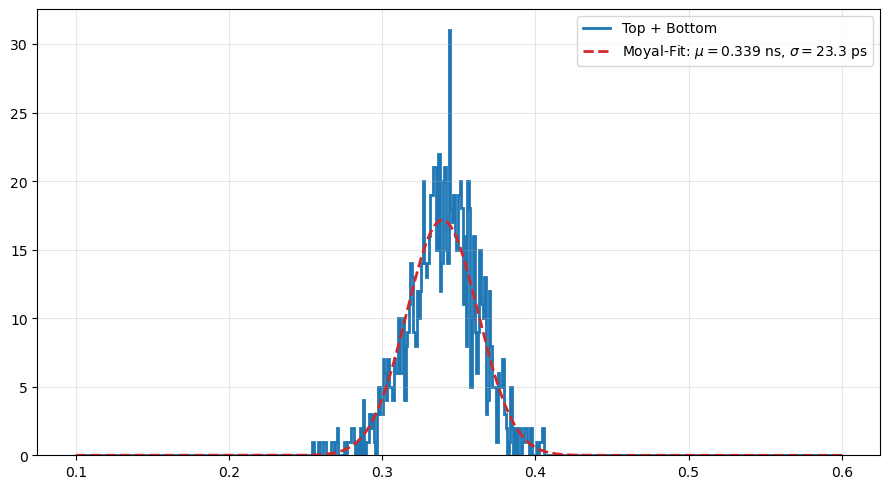

Mittelwert: 0.339335 ns
Moyal-sigma: 23.29 ps
Standardabweichung Moyal-Modell: 23.29 ps
Standardabweichung der Daten:   23.30 ps


In [8]:
# Histogramme pro Event: nur Scintillation-Photonen, Top + Bottom gemeinsam
cumulative_photon_threshold = 40  # Kumulativer Schwellenwert: 40 Photonen ab t=0
histogram_bins = np.linspace(0.1, 0.6, 500)
threshold_times = []
event_histograms = {}
maximum_histogram_counts = []

for event_id, event_data in data_all_scintillation.groupby("EventID"):
    result = {"EventID": event_id}
    event_histograms[event_id] = {}
    all_hit_times = []

    for hit_position in ("top", "bottom"):
        hit_times = (
            event_data.loc[
                event_data["Hit"].astype(str).str.lower() == hit_position,
                "TimeSinceZero"
            ]
            .dropna()
            .sort_values()
            .to_numpy()
        )
        all_hit_times.append(hit_times)

        counts, bin_edges = np.histogram(hit_times, bins=histogram_bins)
        event_histograms[event_id][hit_position] = {
            "counts": counts,
            "bin_edges": bin_edges,
            "times": hit_times
        }

    combined_times = np.sort(np.concatenate(all_hit_times))
    combined_counts, combined_bin_edges = np.histogram(
        combined_times,
        bins=histogram_bins
    )
    event_histograms[event_id]["combined"] = {
        "times": combined_times,
        "counts": combined_counts,
        "bin_edges": combined_bin_edges
    }
    maximum_histogram_counts.append(combined_counts.max())

    # Kumulativer Schwellenwert: Summe von Anfang an
    cumulative_count = 0
    threshold_time_cumulative = np.nan
    for i, count in enumerate(combined_counts):
        cumulative_count += count
        if cumulative_count >= cumulative_photon_threshold:
            # Bin-Mittelpunkt verwenden
            threshold_time_cumulative = (
                combined_bin_edges[i] + combined_bin_edges[i + 1]
            ) / 2
            result["cumulative_photon_count"] = cumulative_count
            break
    
    result["combined_count_threshold_time"] = threshold_time_cumulative
    result["combined_count_threshold"] = result.get("cumulative_photon_count", np.nan)

    threshold_times.append(result)
print(f"Cumulative photon threshold: {cumulative_photon_threshold}")
threshold_times = pd.DataFrame(threshold_times)

print("\nNumber of events crossing the cumulative threshold:")
print(f"Maximum bin count in any event: {max(maximum_histogram_counts)}")
print(threshold_times.head())
print("\nNumber of events crossing the histogram threshold:")
print(threshold_times["combined_count_threshold_time"].notna().sum())

times = threshold_times[
    "combined_count_threshold_time"
].to_numpy(dtype=float)

times = times[np.isfinite(times)]

n = len(times)
n_total = len(threshold_times)

efficiency = n / n_total if n_total else np.nan

print(f"Events mit Threshold: {n} / {n_total}")
print(f"Threshold-Effizienz: {efficiency:.1%}")

if n < 2:
    print("Zu wenige gültige Events für eine Auswertung.")

elif np.ptp(times) == 0:
    print(
        "Alle Zeiten liegen im selben Zeit-Bin. "
        "Die Zeitstreuung ist mit diesem Raster nicht aufgelöst."
    )

else:
    # Moyal-Modell für die gespeicherten Bin-Mittelpunkte
    # loc, scale = moyal.fit(times)

    loc, scale = norm.fit(times)

    # Gaussian fit
    loc, scale = norm.fit(times)

    # Use the Gaussian distribution in the plotting code below
    moyal = norm
    moyal_mean = loc
    moyal_sigma = scale

    # Mittelwert und Standardabweichung der Moyal-Verteilung
    moyal_mean = moyal.mean(loc=loc, scale=scale)
    moyal_sigma = moyal.std(loc=loc, scale=scale)

    # Exakt dasselbe Raster wie bei der Threshold-Bestimmung
    counts, bin_edges = np.histogram(times, bins=histogram_bins)

    # Erwartete Events pro Bin statt PDF × Binbreite
    bin_width = bin_edges[1] - bin_edges[0]

    fit_times = np.linspace(bin_edges[0], bin_edges[-1], 5000)
    fit_counts = (
        n * bin_width * moyal.pdf(fit_times, loc=loc, scale=scale)
    )

    # Sichtbaren Bereich auf belegte Bins plus Rand beschränken
    occupied = np.flatnonzero(counts)
    first = max(occupied[0] - 2, 0)
    last = min(occupied[-1] + 2, len(counts) - 1)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.stairs(
        counts,
        bin_edges,
        linewidth=2,
        color="tab:blue",
        label="Top + Bottom"
    )

    ax.plot(
        fit_times,
        fit_counts,
        color="tab:red",
        linewidth=2,
        linestyle="--",
        label=(
            f"Moyal-Fit: "
            f"$\\mu={moyal_mean:.3f}$ ns, "
            f"$\\sigma={moyal_sigma * 1000:.1f}$ ps"
        )
    )

    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()

    # Vor show() speichern, falls save_plot die aktuelle Figur verwendet
    save_plot("combined_threshold_times_gaussian_fit")
    plt.show()

    print(f"Mittelwert: {moyal_mean:.6f} ns")
    print(
        f"Moyal-sigma: {moyal_sigma * 1000:.2f} ps"
    )

    sigma_data = np.std(times, ddof=1)

    print(f"Standardabweichung Moyal-Modell: {moyal_sigma * 1000:.2f} ps")
    print(f"Standardabweichung der Daten:   {sigma_data * 1000:.2f} ps")

TOP: 1000 Events mit Threshold
BOTTOM: 1000 Events mit Threshold


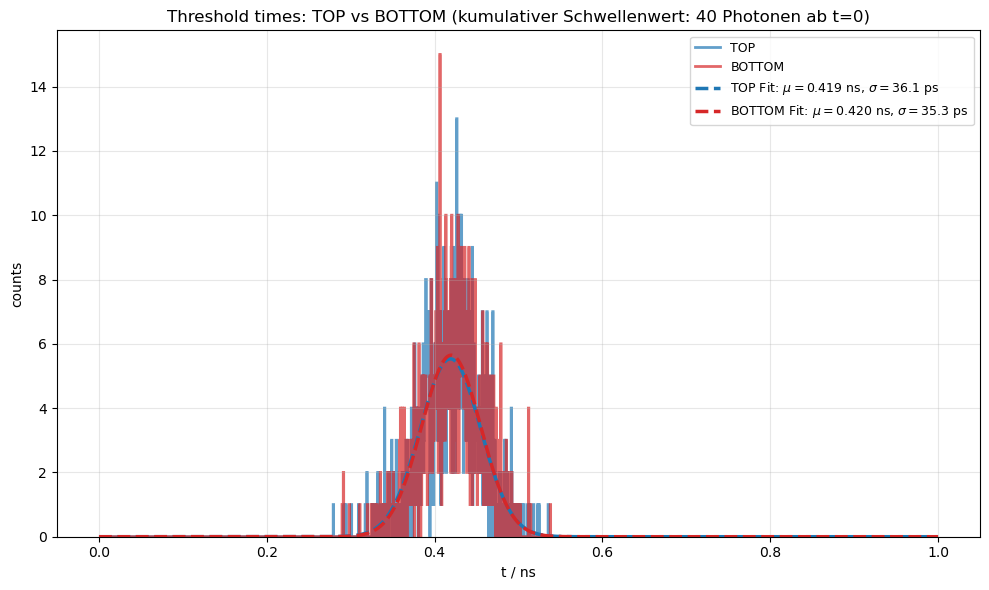


=== TOP Analysis ===
Mean: 0.418803 ns
Sigma: 36.07 ps

=== BOTTOM Analysis ===
Mean: 0.419657 ns
Sigma: 35.35 ps
Sigma_s BOTTOM: 78.53 ps
Sigma_s TOP: 80.13 ps
Sigma_s TOP: 80.13 ps


In [9]:
# Separate Analyse für TOP und BOTTOM
cumulative_photon_threshold = 40  # Kumulativer Schwellenwert: 40 Photonen ab t=0
histogram_bins = np.linspace(0, 1, 2000)

threshold_times_top = []
threshold_times_bottom = []

for event_id, event_data in data_all_scintillation.groupby("EventID"):
    # TOP
    hit_times_top = (
        event_data.loc[
            event_data["Hit"].astype(str).str.lower() == "top",
            "TimeSinceZero"
        ]
        .dropna()
        .to_numpy()
    )
    
    if len(hit_times_top) > 0:
        counts_top, bin_edges_top = np.histogram(hit_times_top, bins=histogram_bins)
        # Kumulativer Schwellenwert
        cumulative_top = 0
        for i, count in enumerate(counts_top):
            cumulative_top += count
            if cumulative_top >= cumulative_photon_threshold:
                threshold_time_top = (
                    bin_edges_top[i] + bin_edges_top[i + 1]
                ) / 2
                threshold_times_top.append(threshold_time_top)
                break
    
    # BOTTOM
    hit_times_bottom = (
        event_data.loc[
            event_data["Hit"].astype(str).str.lower() == "bottom",
            "TimeSinceZero"
        ]
        .dropna()
        .to_numpy()
    )
    
    if len(hit_times_bottom) > 0:
        counts_bottom, bin_edges_bottom = np.histogram(hit_times_bottom, bins=histogram_bins)
        # Kumulativer Schwellenwert
        cumulative_bottom = 0
        for i, count in enumerate(counts_bottom):
            cumulative_bottom += count
            if cumulative_bottom >= cumulative_photon_threshold:
                threshold_time_bottom = (
                    bin_edges_bottom[i] + bin_edges_bottom[i + 1]
                ) / 2
                threshold_times_bottom.append(threshold_time_bottom)
                break

# Konvertiere zu Arrays
times_top = np.array(threshold_times_top)
times_bottom = np.array(threshold_times_bottom)

print(f"TOP: {len(times_top)} Events mit Threshold")
print(f"BOTTOM: {len(times_bottom)} Events mit Threshold")

# Define the Moyal distribution function for fitting
def moyal_distribution(x, loc, scale):
    return moyal.pdf(x, loc=loc, scale=scale)

# Fits: Fit a Landau (Moyal) distribution to the threshold times
if len(times_top) > 1:
    loc_top, scale_top = moyal.fit(times_top)
    moyal_mean_top = moyal.mean(loc=loc_top, scale=scale_top)
    moyal_sigma_top = moyal.std(loc=loc_top, scale=scale_top)
else:
    moyal_mean_top = moyal_sigma_top = np.nan

if len(times_bottom) > 1:
    loc_bottom, scale_bottom = moyal.fit(times_bottom)
    moyal_mean_bottom = moyal.mean(loc=loc_bottom, scale=scale_bottom)
    moyal_sigma_bottom = moyal.std(loc=loc_bottom, scale=scale_bottom)
else:
    moyal_mean_bottom = moyal_sigma_bottom = np.nan

# Histogramme
counts_top_hist, bin_edges_hist = np.histogram(times_top, bins=histogram_bins)
counts_bottom_hist, _ = np.histogram(times_bottom, bins=histogram_bins)

bin_width = bin_edges_hist[1] - bin_edges_hist[0]

fit_times_range = np.linspace(bin_edges_hist[0], bin_edges_hist[-1], 5000)

# Plots
fig, ax = plt.subplots(figsize=(10, 6))

ax.stairs(
    counts_top_hist,
    bin_edges_hist,
    linewidth=2,
    color="tab:blue",
    label="TOP",
    alpha=0.7
)

ax.stairs(
    counts_bottom_hist,
    bin_edges_hist,
    linewidth=2,
    color="tab:red",
    label="BOTTOM",
    alpha=0.7
)

if len(times_top) > 1:
    fit_top = len(times_top) * bin_width * moyal.pdf(fit_times_range, loc=loc_top, scale=scale_top)
    ax.plot(
        fit_times_range,
        fit_top,
        color="tab:blue",
        linewidth=2.5,
        linestyle="--",
        label=(
            f"TOP Fit: "
            f"$\\mu={moyal_mean_top:.3f}$ ns, "
            f"$\\sigma={moyal_sigma_top * 1000:.1f}$ ps"
        )
    )

if len(times_bottom) > 1:
    fit_bottom = len(times_bottom) * bin_width * moyal.pdf(fit_times_range, loc=loc_bottom, scale=scale_bottom)
    ax.plot(
        fit_times_range,
        fit_bottom,
        color="tab:red",
        linewidth=2.5,
        linestyle="--",
        label=(
            f"BOTTOM Fit: "
            f"$\\mu={moyal_mean_bottom:.3f}$ ns, "
            f"$\\sigma={moyal_sigma_bottom * 1000:.1f}$ ps"
        )
    )
    f"Threshold times: TOP vs BOTTOM (kumulativer Schwellenwert: {cumulative_photon_threshold} Photonen ab t=0)"
ax.set_xlabel("t / ns")
ax.set_ylabel("counts")
ax.set_title(
    f"Threshold times: TOP vs BOTTOM (kumulativer Schwellenwert: {cumulative_photon_threshold} Photonen ab t=0)"
)

ax.grid(alpha=0.3)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

save_plot("threshold_times_top_vs_bottom")
plt.show()

print("\n=== TOP Analysis ===")
print(f"Mean: {moyal_mean_top:.6f} ns")
print(f"Sigma: {moyal_sigma_top * 1000:.2f} ps")

print("\n=== BOTTOM Analysis ===")
print(f"Mean: {moyal_mean_bottom:.6f} ns")
print(f"Sigma: {moyal_sigma_bottom * 1000:.2f} ps")

sigma_s_top = (np.pi / np.sqrt(2)) * moyal_sigma_top

sigma_s_bottom = (np.pi / np.sqrt(2)) * moyal_sigma_bottom
print(f"Sigma_s BOTTOM: {sigma_s_bottom * 1000:.2f} ps")
sigma_s_top = (np.pi / np.sqrt(2)) * moyal_sigma_top
print(f"Sigma_s TOP: {sigma_s_top * 1000:.2f} ps")

print(f"Sigma_s TOP: {sigma_s_top * 1000:.2f} ps")